<a href="https://colab.research.google.com/github/ushkgowda/Supermarket-Sales-Analysis/blob/main/project1_sales_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 1: Supermarket Sales Analysis
**Portfolio: Multi-Domain Data Analysis** | Domain: Retail

**Goals:** analyze daily sales patterns, identify best-selling product lines, understand customer behavior, validate data quality and turn findings into recommendations.

**Dataset:** `supermarket_sales.csv`, 2,000 invoices, Jan-Dec 2023, 3 branches.

**Key finding up front:** sales are very evenly spread. No segment difference (product, branch, hour, weekday, customer type, payment) is statistically significant, so rankings below are descriptive.

## 1. Setup and loading

In [5]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

df = pd.read_csv("/content/supermarket_sales.csv")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Shape: (2000, 14)
Columns: ['Invoice_ID', 'Branch', 'City', 'Customer_Type', 'Gender', 'Product_Line', 'Unit_Price', 'Quantity', 'Tax', 'Total', 'Date', 'Time', 'Payment', 'Rating']


,Invoice_ID,Branch,City,Customer_Type,Gender,Product_Line,Unit_Price,Quantity,Tax,Total,Date,Time,Payment,Rating
0,INV000001,B,Mandalay,Member,Male,Food & Beverages,69.36,3,7.28,119.58,2023-08-08,18:54,Credit card,8.4
1,INV000002,C,Mandalay,Member,Female,Food & Beverages,35.25,1,6.62,137.13,2023-02-09,18:44,Credit card,4.3
2,INV000003,C,Naypyitaw,Normal,Female,Fashion Accessories,57.56,8,4.66,490.48,2023-08-24,16:16,Cash,9.6
3,INV000004,B,Naypyitaw,Member,Female,Food & Beverages,16.60,5,8.57,142.54,2023-02-09,11:35,Cash,4.5
4,INV000005,C,Yangon,Normal,Female,Food & Beverages,49.07,1,3.70,24.43,2023-07-04,8:56,Credit card,5.8


## 2. Data validation and quality checks

In [6]:
print("Missing values per column:"); print(df.isnull().sum().to_string())
print("\nDuplicate invoice IDs:", df.Invoice_ID.duplicated().sum())
print("Negative numeric values:", int((df[["Unit_Price","Quantity","Tax","Total"]] < 0).sum().sum()))
print("Ratings outside 0-10:", int(((df.Rating < 0) | (df.Rating > 10)).sum()))
df.describe().round(2)

Missing values per column:
Invoice_ID       0
Branch           0
City             0
Customer_Type    0
Gender           0
Product_Line     0
Unit_Price       0
Quantity         0
Tax              0
Total            0
Date             0
Time             0
Payment          0
Rating           0

Duplicate invoice IDs: 0
Negative numeric values: 0
Ratings outside 0-10: 0


,Unit_Price,Quantity,Tax,Total,Rating
count,2000.00,2000.00,2000.00,2000.00,2000.00
mean,55.26,5.03,5.51,259.64,6.96
std,25.81,2.61,2.58,138.93,1.73
min,10.01,1.00,1.00,20.37,4.00
25%,33.61,3.00,3.32,137.87,5.40
50%,55.61,5.00,5.44,258.04,6.95
75%,77.50,7.00,7.74,386.94,8.40
max,99.92,9.00,10.00,499.91,10.00


In [7]:
# Consistency checks: do the numbers agree with each other?
gross = df.Unit_Price * df.Quantity
print("Rows where Total == Unit_Price * Quantity:", int(np.isclose(gross, df.Total, atol=0.05).sum()), "of", len(df))
print("Rows within 5%:", int((abs(gross - df.Total) / gross <= 0.05).sum()))
print("Mean absolute gap:", round((gross - df.Total).abs().mean(), 2))

rate = df.Tax / gross
print("\nImplied tax rate (Tax / gross): median %.1f%%, IQR %.1f%%-%.1f%%" % (rate.median()*100, rate.quantile(.25)*100, rate.quantile(.75)*100))

print("\nBranches per city (a clean mapping would show 1):")
print(pd.crosstab(df.Branch, df.City))

Rows where Total == Unit_Price * Quantity: 0 of 2000
Rows within 5%: 80
Mean absolute gap: 199.61

Implied tax rate (Tax / gross): median 2.2%, IQR 1.1%-4.9%

Branches per city (a clean mapping would show 1):
City    Mandalay  Naypyitaw  Yangon
Branch                             
A            206        228     240
B            237        225     234
C            211        211     208


**Validation result:** no missing values, duplicates, negatives or out-of-range ratings. However, `Total` never equals `Unit_Price x Quantity`, `Tax` has no consistent rate, and every branch appears in all three cities. We keep the recorded `Total` as given and flag this limitation in the report.

## 3. Cleaning and feature engineering

In [8]:
df["Date"] = pd.to_datetime(df["Date"])
df["Hour"] = pd.to_datetime(df["Time"], format="%H:%M").dt.hour
df["Month"] = df["Date"].dt.to_period("M").astype(str)
days = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
df["Weekday"] = pd.Categorical(df["Date"].dt.day_name(), days, ordered=True)
df["Is_Weekend"] = df["Weekday"].isin(["Saturday","Sunday"])
print("Date range:", df.Date.min().date(), "to", df.Date.max().date(), "| unique days:", df.Date.nunique())

Date range: 2023-01-01 to 2023-12-31 | unique days: 364


## 4. Overview KPIs

In [9]:
daily = df.groupby("Date").Total.sum()
kpis = {
    "Total sales": df.Total.sum(), "Transactions": len(df),
    "Average transaction": df.Total.mean(), "Median transaction": df.Total.median(),
    "Units sold": df.Quantity.sum(), "Average daily sales": daily.mean(),
    "Average rating": df.Rating.mean(),
}
pd.Series(kpis).round(2).to_frame("Value")

,Value
Total sales,519280.69
Transactions,2000.00
Average transaction,259.64
Median transaction,258.04
Units sold,10066.00
Average daily sales,1426.60
Average rating,6.96


## 5. Top performers: product lines

,sales,invoices,avg_basket,units,rating,share_%
Product_Line,,,,,,
Health & Beauty,96970.32,363,267.14,1866,6.99,18.67
Sports & Travel,91177.89,351,259.77,1737,6.93,17.56
Electronic Accessories,88995.19,337,264.08,1691,6.86,17.14
Home & Lifestyle,86351.63,335,257.77,1654,6.97,16.63
Food & Beverages,78233.94,312,250.75,1618,7.05,15.07
Fashion Accessories,77551.72,302,256.79,1500,6.94,14.93


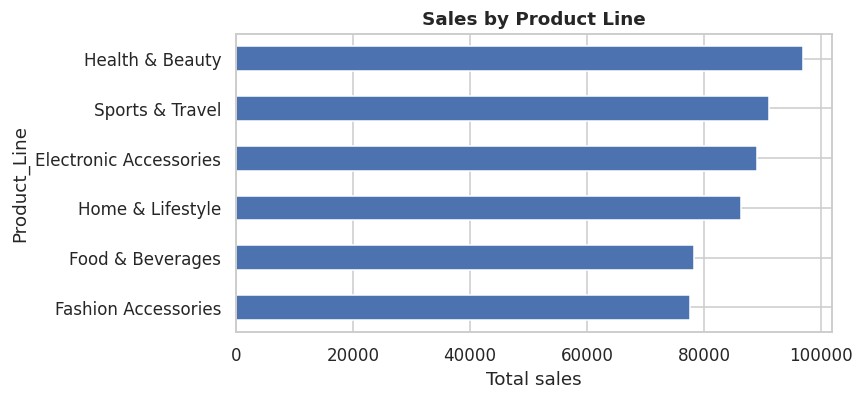

In [10]:
pl = df.groupby("Product_Line").agg(sales=("Total","sum"), invoices=("Total","size"),
        avg_basket=("Total","mean"), units=("Quantity","sum"), rating=("Rating","mean"))
pl["share_%"] = pl.sales / pl.sales.sum() * 100
pl = pl.sort_values("sales", ascending=False).round(2)
display(pl)

fig, ax = plt.subplots(figsize=(8, 3.8))
pl.sales.sort_values().plot.barh(ax=ax, color=sns.color_palette()[0])
ax.set_title("Sales by Product Line"); ax.set_xlabel("Total sales")
plt.tight_layout(); plt.show()

In [11]:
groups = [g.Total.values for _, g in df.groupby("Product_Line")]
print("ANOVA, basket value by product line: p = %.3f" % stats.f_oneway(*groups).pvalue)

ANOVA, basket value by product line: p = 0.721


## 6. Sales trends

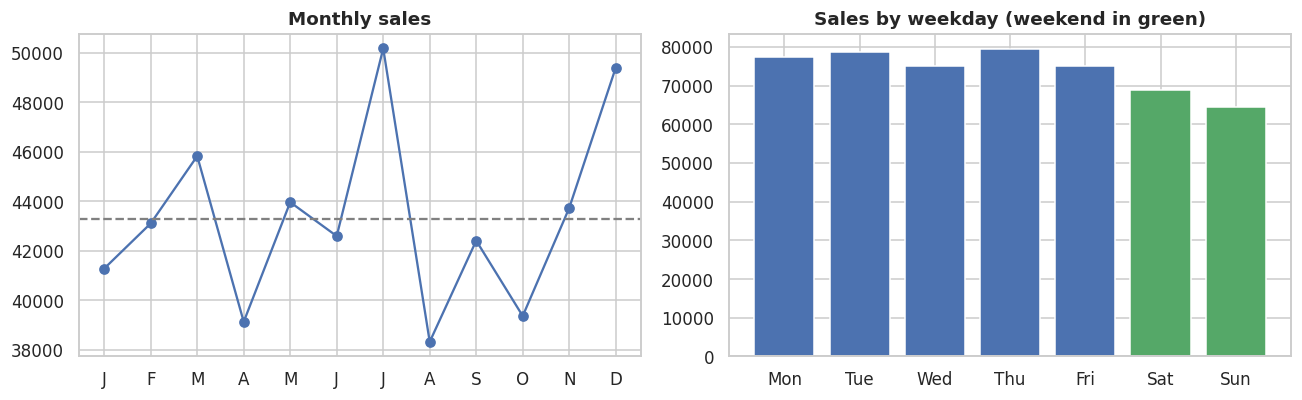

Best month: 2023-07 | weakest: 2023-08
Monthly trend slope = 198 per month, p = 0.553
Weekend share of sales: 25.7% (even spread would be 28.6%)


In [12]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
monthly = df.groupby("Month").Total.sum()
axs[0].plot(range(12), monthly.values, marker="o")
axs[0].axhline(monthly.mean(), ls="--", color="grey")
axs[0].set_xticks(range(12)); axs[0].set_xticklabels(["J","F","M","A","M","J","J","A","S","O","N","D"])
axs[0].set_title("Monthly sales")
wd = df.groupby("Weekday", observed=True).Total.sum()
axs[1].bar([d[:3] for d in days], wd.values, color=["C0"]*5 + ["C2"]*2)
axs[1].set_title("Sales by weekday (weekend in green)")
plt.tight_layout(); plt.show()

x = np.arange(12); r = stats.linregress(x, monthly.values)
print("Best month:", monthly.idxmax(), "| weakest:", monthly.idxmin())
print("Monthly trend slope = %.0f per month, p = %.3f" % (r.slope, r.pvalue))
print("Weekend share of sales: %.1f%% (even spread would be 28.6%%)" % (wd[["Saturday","Sunday"]].sum() / wd.sum() * 100))

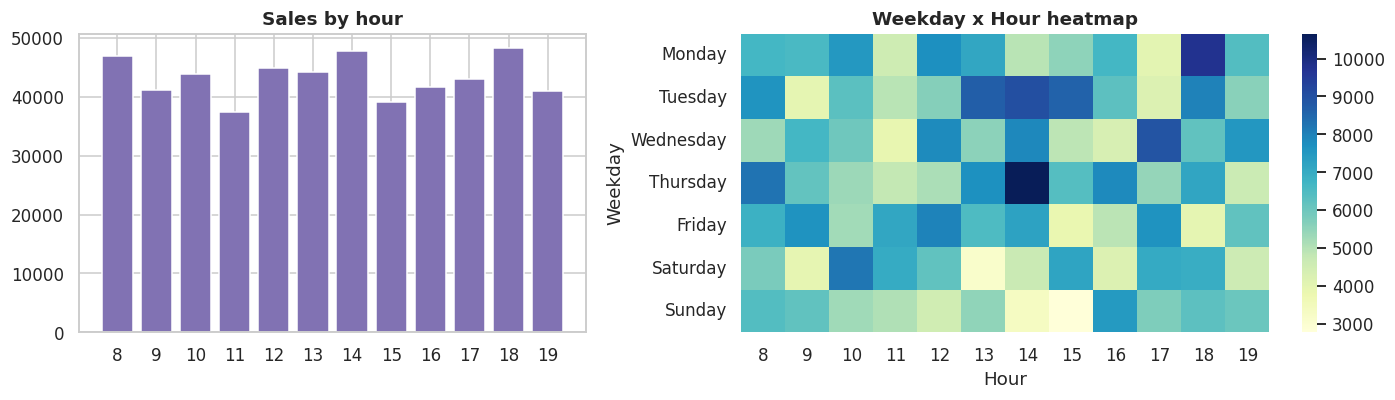

Busiest hours: [18, 14, 8] -> 27.5% of sales (flat would be 25%)


In [13]:
hourly = df.groupby("Hour").Total.sum()
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.3]})
axs[0].bar(hourly.index, hourly.values, color="C4"); axs[0].set_title("Sales by hour"); axs[0].set_xticks(hourly.index)
sns.heatmap(df.pivot_table(index="Weekday", columns="Hour", values="Total", aggfunc="sum", observed=True),
            cmap="YlGnBu", ax=axs[1]); axs[1].set_title("Weekday x Hour heatmap")
plt.tight_layout(); plt.show()

top3 = hourly.nlargest(3)
print("Busiest hours:", top3.index.tolist(), "-> %.1f%% of sales (flat would be 25%%)" % (top3.sum() / hourly.sum() * 100))

## 7. Customer behavior

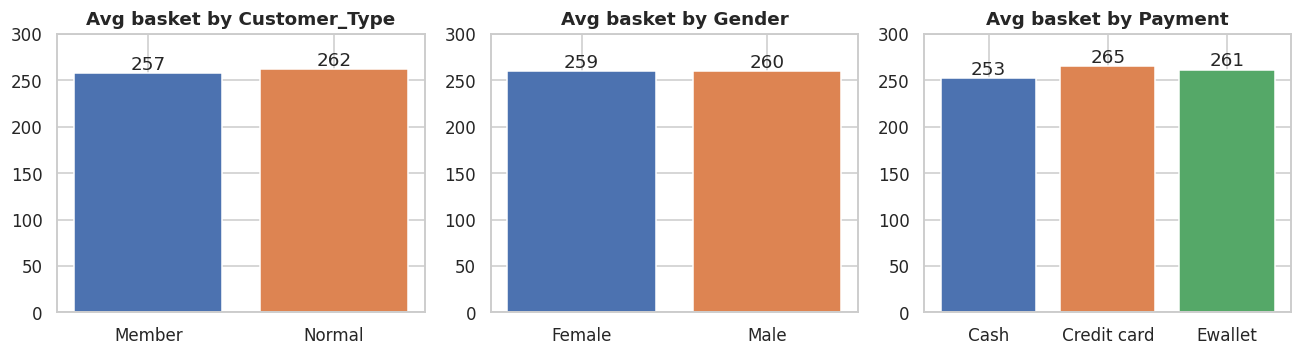

Member vs Normal basket: t-test p = 0.441
Female vs Male basket:   t-test p = 0.939
Payment method ANOVA:    p = 0.241
Low ratings (<5): 17.1% of invoices


In [14]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, col in zip(axs, ["Customer_Type", "Gender", "Payment"]):
    g = df.groupby(col).Total.mean()
    ax.bar(g.index, g.values, color=sns.color_palette()[:len(g)]); ax.set_ylim(0, 300)
    ax.set_title(f"Avg basket by {col}")
    for i, v in enumerate(g.values): ax.text(i, v + 4, f"{v:.0f}", ha="center")
plt.tight_layout(); plt.show()

m, n = df[df.Customer_Type=="Member"].Total, df[df.Customer_Type=="Normal"].Total
f, ma = df[df.Gender=="Female"].Total, df[df.Gender=="Male"].Total
print("Member vs Normal basket: t-test p = %.3f" % stats.ttest_ind(m, n, equal_var=False).pvalue)
print("Female vs Male basket:   t-test p = %.3f" % stats.ttest_ind(f, ma, equal_var=False).pvalue)
print("Payment method ANOVA:    p = %.3f" % stats.f_oneway(*[g.Total.values for _, g in df.groupby("Payment")]).pvalue)
print("Low ratings (<5): %.1f%% of invoices" % ((df.Rating < 5).mean() * 100))

## 8. Branch performance and correlations

,sales,invoices,avg_basket,rating
Branch,,,,
A,179047.93,674,265.65,6.92
B,180821.79,696,259.80,6.97
C,159410.97,630,253.03,6.98


Branch ANOVA on basket value: p = 0.261


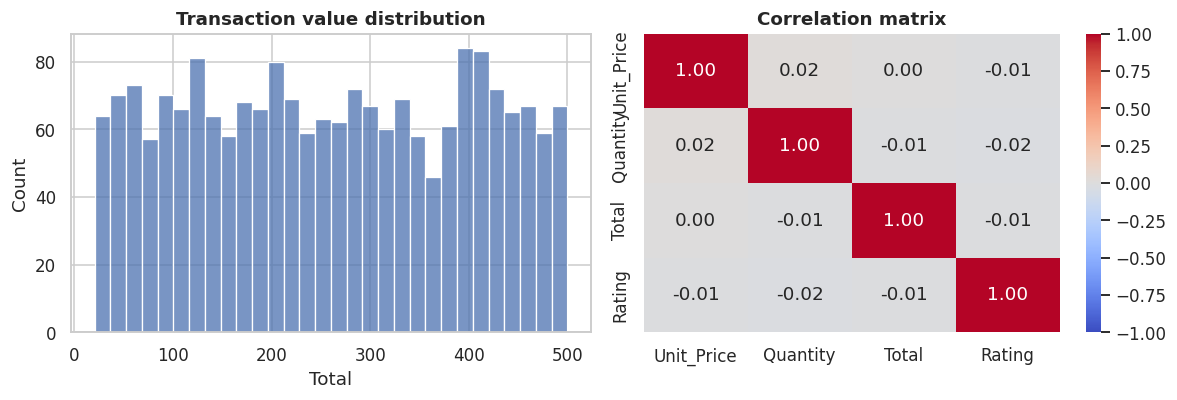

In [15]:
b = df.groupby("Branch").agg(sales=("Total","sum"), invoices=("Total","size"), avg_basket=("Total","mean"), rating=("Rating","mean")).round(2)
display(b)
print("Branch ANOVA on basket value: p = %.3f" % stats.f_oneway(*[g.Total.values for _, g in df.groupby("Branch")]).pvalue)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df.Total, bins=30, ax=axs[0]); axs[0].set_title("Transaction value distribution")
sns.heatmap(df[["Unit_Price","Quantity","Total","Rating"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axs[1])
axs[1].set_title("Correlation matrix"); plt.tight_layout(); plt.show()

## 9. Findings

| Area | Finding | Significant? |
|---|---|---|
| Products | Health & Beauty leads (about 18.7% of sales), Fashion Accessories lowest (about 14.9%) | No |
| Timing | Thursday is the best weekday, Sunday the weakest; weekends are below average | No |
| Hours | Peaks at 08:00, 14:00 and 18:00 | No |
| Customers | Members spend no more than non-members | No |
| Branches | Branch C about 13% below B, driven by invoice count | No |
| Data quality | Total, Tax and branch-city mapping do not reconcile | Confirmed |

## 10. Recommendations
1. **Fix data capture** (totals, tax, branch-city mapping) before any financial decisions.
2. **Pilot, do not assume:** run measured weekend and product-line promotions with control groups.
3. **Investigate Branch C traffic**, since basket value is not the issue.
4. **Review loyalty benefits**, since members do not spend more per visit.
5. **Add modest staffing buffers** around 08:00, 14:00 and 18:00.
6. **Capture reasons for low ratings** (17% of invoices are below 5).

**Limitations:** 2,000 invoices over 12 months suggests a sample; no cost or margin data; multiple tests run without adjustment.